# Fusion: the FT-Transformer with each graph model of the team

Our FT-Transformer (column sets A and B, seeds 42, 1 and 2) combined with each graph model of the team study: GraphSAGE (ours), R-GCN, HAN and GAT (from teammates). Every fusion was made by the team's shared `fusion.py`, unchanged, through `run_fusion.py`, which saved its tables in `results/fusion/`. This notebook shows those tables and a figure, and in section D runs the fusion again to show that the saved results come out the same. Graph models whose fusion is not finished yet are left out.

## Setup

Loads the saved results. Nothing is trained here, and no GPU is needed. In Colab it first connects Google Drive; on the PC it finds the project folder by itself.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:   # in Colab: work in the project folder in Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/IEEE Fraud Detection")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.dont_write_bytecode = True   # no __pycache__ folder in the project

import pandas as pd
import report
import run_fusion

pd.set_option("display.max_colwidth", None, "display.max_columns", None)
print("Fusion finished for:", ", ".join(report.GRAPHS[g] for g in report.fusion_graphs()))

Fusion finished for: R-GCN, HAN


## How the fusion works

For each column set (A, B) and seed (42, 1, 2), with the graph model of the same seed:
- **score = z(FT-Transformer) + alpha × z(graph model)**, where z puts each model's scores on the same scale (mean and standard deviation of its own validation scores);
- **alpha** is one of 0, 0.025, ..., 1: the one with the best **validation** PR-AUC (alpha = 0 means the graph adds nothing);
- then the **test** set is scored once, with alpha fixed, and the same is done with the graph model trained on **shuffled links** (the control).

**A graph counts as helping only if all three of the team plan's checks hold** (per column set and metric):
1. the 95% interval of the gain (fused minus FT-Transformer alone, mean over seeds, 2,000 paired bootstrap resamples of the test payments) lies above 0;
2. the gain is larger than the spread between the FT-Transformer's own seeds (highest minus lowest);
3. the 95% interval of real minus shuffled links lies above 0: the links themselves carry information.

## A. Does each graph model help on top of the FT-Transformer?

Test set. FT alone and Fused: mean over the 3 seeds, lowest and highest seed in brackets. Gains and differences have 4 decimals because they are small. PR-AUC is the main metric (3.5% of payments are fraud).

In [2]:
report.fusion_summary_table()

,Graph model,FT-Transformer on,Metric,FT alone,Fused,Gain,"Gain, 95% interval",1. Interval above 0,2. Gain > seed spread,"Fused, shuffled links",Real - shuffled,"Real - shuffled, 95% interval",3. Real beats shuffled,Graph helps,"Alpha (seeds 42, 1, 2)"
0,R-GCN,set A (with V),ROC-AUC,0.853 (0.847-0.856),0.865 (0.863-0.867),+0.0124,+0.0100 to +0.0148,✓,✓ (spread 0.0092),0.864,+0.0011,+0.0004 to +0.0017,✓,yes,0.350 0.550 0.450
1,R-GCN,set A (with V),PR-AUC,0.403 (0.396-0.416),0.415 (0.405-0.424),+0.0115,+0.0086 to +0.0144,✓,✗ (spread 0.0199),0.414,+0.0004,-0.0004 to +0.0011,✗,no,0.350 0.550 0.450
2,R-GCN,set B (no V),ROC-AUC,0.757 (0.751-0.763),0.787 (0.783-0.791),+0.0305,+0.0258 to +0.0353,✓,✓ (spread 0.0112),0.785,+0.0021,+0.0009 to +0.0033,✓,yes,1.000 1.000 0.625
3,R-GCN,set B (no V),PR-AUC,0.214 (0.202-0.222),0.216 (0.203-0.224),+0.0018,-0.0012 to +0.0048,✗,✗ (spread 0.0195),0.217,-0.0009,-0.0020 to +0.0001,✗,no,1.000 1.000 0.625
4,HAN,set A (with V),ROC-AUC,0.853 (0.847-0.856),0.864 (0.860-0.867),+0.0113,+0.0094 to +0.0132,✓,✓ (spread 0.0092),0.861,+0.0028,+0.0019 to +0.0037,✓,yes,0.100 0.375 0.450
5,HAN,set A (with V),PR-AUC,0.403 (0.396-0.416),0.416 (0.412-0.419),+0.0125,+0.0100 to +0.0152,✓,✗ (spread 0.0199),0.412,+0.0033,+0.0022 to +0.0044,✓,no,0.100 0.375 0.450
6,HAN,set B (no V),ROC-AUC,0.757 (0.751-0.763),0.788 (0.775-0.796),+0.0311,+0.0272 to +0.0351,✓,✓ (spread 0.0112),0.778,+0.0098,+0.0080 to +0.0115,✓,yes,0.425 0.825 0.575
7,HAN,set B (no V),PR-AUC,0.214 (0.202-0.222),0.217 (0.206-0.225),+0.0028,+0.0003 to +0.0055,✓,✗ (spread 0.0195),0.216,+0.0008,-0.0008 to +0.0025,✗,no,0.425 0.825 0.575


The same as a picture. Blue: the gain over the FT-Transformer alone. Grey: fused with the real links minus fused with the shuffled links. Dots are seeds, the bar is the mean and the line is the 95% interval; right of the 0 line means better.

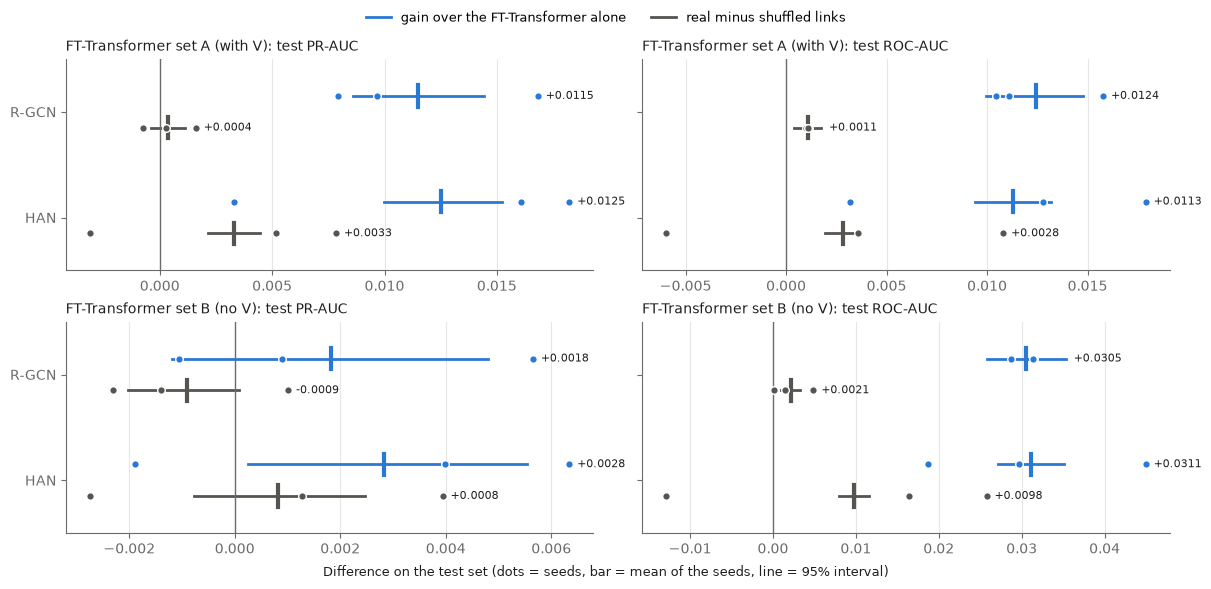

In [3]:
report.fig_fusion()

## B. Seed by seed

The weight alpha that validation chose, validation PR-AUC before and after fusion, the test scores of the graph model alone, the FT-Transformer alone, the fused score and the fused score with shuffled links, and the share of all test frauds caught when the top 1% or 5% of payments by score are reviewed (team plan p. 11).

In [4]:
report.fusion_seed_table()

,Graph model,FT-Transformer on,Seed,Alpha,"Alpha, shuffled",Val PR-AUC: FT alone -> fused,Test PR-AUC: graph alone,Test PR-AUC: FT alone,Test PR-AUC: fused,"Test PR-AUC: fused, shuffled links",Test ROC-AUC: graph alone,Test ROC-AUC: FT alone,Test ROC-AUC: fused,"Test ROC-AUC: fused, shuffled links","Frauds caught, top 1%: FT alone -> fused","Frauds caught, top 5%: FT alone -> fused"
0,R-GCN,set A (with V),42,0.350,0.350,0.419 -> 0.432,0.156,0.416,0.424,0.423,0.761,0.856,0.867,0.866,23.3% -> 23.2%,45.8% -> 46.0%
1,R-GCN,set A (with V),1,0.550,0.450,0.409 -> 0.430,0.147,0.396,0.405,0.406,0.749,0.854,0.864,0.863,22.5% -> 23.1%,44.7% -> 45.6%
2,R-GCN,set A (with V),2,0.450,0.425,0.416 -> 0.435,0.133,0.398,0.415,0.413,0.760,0.847,0.863,0.862,22.0% -> 22.5%,45.7% -> 47.6%
3,R-GCN,set B (no V),42,1.000,1.000,0.258 -> 0.277,0.156,0.219,0.224,0.223,0.761,0.757,0.788,0.787,12.9% -> 13.1%,36.1% -> 36.0%
4,R-GCN,set B (no V),1,1.000,1.000,0.245 -> 0.262,0.147,0.202,0.203,0.204,0.749,0.751,0.783,0.783,12.3% -> 12.4%,33.5% -> 31.9%
5,R-GCN,set B (no V),2,0.625,0.425,0.264 -> 0.272,0.133,0.222,0.221,0.223,0.760,0.763,0.791,0.786,13.6% -> 13.3%,36.1% -> 35.5%
6,HAN,set A (with V),42,0.100,0.275,0.419 -> 0.421,0.142,0.416,0.419,0.422,0.754,0.856,0.860,0.865,23.3% -> 23.2%,45.8% -> 46.1%
7,HAN,set A (with V),1,0.375,0.275,0.409 -> 0.429,0.143,0.396,0.412,0.404,0.770,0.854,0.867,0.863,22.5% -> 23.4%,44.7% -> 46.3%
8,HAN,set A (with V),2,0.450,0.150,0.416 -> 0.437,0.133,0.398,0.416,0.411,0.758,0.847,0.865,0.854,22.0% -> 22.5%,45.7% -> 47.5%
9,HAN,set B (no V),42,0.425,0.625,0.258 -> 0.265,0.142,0.219,0.225,0.224,0.754,0.757,0.775,0.788,12.9% -> 12.9%,36.1% -> 36.8%


## C. Where these numbers come from

`results/fusion/fusion_<graph>_ft.csv` and `fusion_<graph>_ft_summary.csv` are written by `fusion.py` itself; `fusion_<graph>_ft_inputs.json` records the SHA-256 of `fusion.py`, of the 24 score files it read and of both tables. Before saving, `run_fusion.py` checked that the FT-Transformer-alone test scores in the table equal `results/graph_vs_V/runs.csv`.

## D. Proof: run the fusion again

For every finished graph model: is `fusion.py` the same file, are the 24 score files the same files (SHA-256), and does running the fusion again from them give the same numbers as the saved tables? Takes about 3 minutes per graph model.

In [5]:
pd.DataFrame([run_fusion.recheck(graph) for graph in report.fusion_graphs()])

,Graph model,Fused on,Same fusion.py,Same 24 score files,Same results when run again
0,rgcn,2026-11-09 21:56,✓,✓,✓
1,han,2026-11-09 21:59,✓,✓,✓


Every figure is also saved to `results/figures/`.